# Modèle de régression linéaire régularisée
Test de 3 régressions pour faire le meilleur choix et les comparer entre elles :
- Ridge : régression linéaire L2, qui somme les carrés des coefficients tout en conservant toutes les features et en répartissant le poids entre elles. Elle rétrécit donc les coefficients mais conserve du bruit.
- Lasso : régression linéaire L1, qui somme les valeurs absolues des coefficients et met certains coefficients à zéro pour sélectionner les variables. Parmi des variables corrélées, il en garde une de façon plutôt arbitraire : sa sélection est instable et peut éliminer des variables utiles.
- Elastic Net : combinaison linéaire de L1 et L2, qui sélectionne ou élimine des variables par groupes. Elle gère bien les groupes de variables corrélées, mais elle est plus complexe à paramétrer à cause de ses deux hyperparamètres.

Split temporel par date de votation : train → validation → test (les plus récentes), identique à celui du modèle de boosting.
Les hyperparamètres et le prétraitement se choisissent par validation croisée temporelle dans le train ; la validation sert à comparer les modèles ; le test ne se regarde qu'une fois, à la fin.

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Racine du dépôt, retrouvée depuis le dossier de lancement du notebook.
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "environment.yml").exists())
ROOT = REPO / "data" / "processed" / "modeling"
OUT_DIR = REPO / "reports" / "generated" / "regularized_linear"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Colonne entièrement vide sur une période : comportement attendu (voir section Features)
warnings.filterwarnings("ignore", message="Skipping features without any observed values")

# Configuration 
TARGET, DATE_COL = "yes_share", "vote_date"
FEATURE_ROLES = ["numeric_candidate", "categorical_candidate", "missing_indicator"]
EXCLUDE = []           # ex. ["history_mean_yes", "history_n_objects"] pour tester sans historique
EXTRA_FEATURES = []    # ex. ["canton"]
MERGE_CENTRE = True    # fusionne PDC + PBD + Centre (justification plus loin)

# Partitions communes avec 01_hist_gradient_boosting (dates entières)
TRAIN_END = pd.Timestamp("2020-12-31")        # entraînement : jusqu'à fin 2020
VALIDATION_END = pd.Timestamp("2022-12-31")   # validation : 2021-2022 ; test : 2023-2025 (réservé)

print("Repo :", REPO)
print("Données trouvées :", (ROOT / "municipal_structured.parquet").exists())

Repo : C:\Users\Victus\Documents\heig_vd\gml\GML-Swiss-Voting
Données trouvées : True


## 1. Données et features

**Fusion PDC / PBD / Centre.** Après l'élection de 2023, `party_share_pdc` et `party_share_pbd` sont vides et seul
`party_share_centre` est rempli (le PDC et le PBD ont fusionné en 2021). Sans correction, environ 60 % des lignes de
test (votations 2024-2025) auraient le PDC à 0 et un Centre jamais vu à l'entraînement. Avec `MERGE_CENTRE = True`,
on additionne les trois en `party_share_centre_bloc`, qui garde le même sens avant et après la fusion.

In [2]:
fd = pd.read_csv(ROOT / "feature_dictionary.csv")
df = pd.read_parquet(ROOT / "municipal_structured.parquet")
df[DATE_COL] = pd.to_datetime(df[DATE_COL])

role = fd.set_index("column")["role"].to_dict()
features = fd[fd["role"].isin(FEATURE_ROLES)]["column"].tolist() + EXTRA_FEATURES
features = [c for c in dict.fromkeys(features) if c in df.columns and c not in EXCLUDE]

if MERGE_CENTRE:
    centre_cols = ["party_share_pdc", "party_share_pbd", "party_share_centre"]
    df["party_share_centre_bloc"] = df[centre_cols].astype("float64").sum(axis=1, min_count=1)
    features = [c for c in features if c not in centre_cols] + ["party_share_centre_bloc"]

party = [c for c in features if c.startswith("party_share_")]
flags = [c for c in features if role.get(c) == "missing_indicator"]
cat = [c for c in features if role.get(c) == "categorical_candidate"
       or (c in EXTRA_FEATURES and not pd.api.types.is_numeric_dtype(df[c]))]
num = [c for c in features if c not in party + flags + cat]

# Types pandas nullables -> types numpy classiques (sinon l'imputer plante sur pd.NA)
for c in party + num:
    df[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")
for c in flags:
    df[c] = df[c].astype("int8")
for c in cat:
    df[c] = df[c].astype(object).where(df[c].notna(), np.nan)

df = df.dropna(subset=[TARGET]).sort_values(DATE_COL).reset_index(drop=True)
print(f"{len(df):,} lignes | {len(features)} features : "
      f"{len(num)} num, {len(party)} partis, {len(flags)} indicateurs, {len(cat)} cat")

262,981 lignes | 26 features : 10 num, 7 partis, 3 indicateurs, 6 cat


## 2. Split temporel train / validation / test

Le découpage se fait **par date de votation**, pas par ligne : toutes les communes d'une même date vont dans le même ensemble.
Les 20 % de dates les plus récentes forment le test, puis les 20 % suivantes (en remontant) la validation, le reste est le train.
Le modèle n'est donc jamais entraîné sur le futur de ce qu'il prédit.

In [3]:
dates = df[DATE_COL]
is_tr = dates.le(TRAIN_END).to_numpy()
is_val = (dates.gt(TRAIN_END) & dates.le(VALIDATION_END)).to_numpy()
is_te = dates.gt(VALIDATION_END).to_numpy()
train_dates, val_dates, test_dates = (np.sort(dates[m].unique()) for m in (is_tr, is_val, is_te))

# Historique communal figé à la fin de l'entraînement  
# Entraînement : historique de la table (dates strictement antérieures).
# Validation et test : historique de la commune à la 1re date de validation, soit exactement
# les résultats antérieurs à la fin de l'entraînement ; aucun résultat de validation ou de test.
first_val = val_dates[0]
assert train_dates[-1] < first_val
hist_cols = ["history_mean_yes", "history_n_objects"]
snap_rows = df[dates.eq(first_val)]
assert snap_rows.groupby("municipality_id")[hist_cols].nunique(dropna=False).le(1).all().all()
snap = snap_rows.groupby("municipality_id")[hist_cols].first()
late = ~is_tr
df["history_mean_yes"] = df["history_mean_yes"].astype("float64")
df["history_n_objects"] = df["history_n_objects"].astype("float64")
df.loc[late, "history_mean_yes"] = df.loc[late, "municipality_id"].map(snap["history_mean_yes"].astype("float64"))
df.loc[late, "history_n_objects"] = df.loc[late, "municipality_id"].map(snap["history_n_objects"].astype("float64")).fillna(0)
df["history_missing"] = df["history_mean_yes"].isna().astype("int8")

X_tr, X_val, X_te = (df.loc[m, features] for m in (is_tr, is_val, is_te))
y_tr, y_val, y_te = (df.loc[m, TARGET].astype("float64") for m in (is_tr, is_val, is_te))

for name, d, X in [("train", train_dates, X_tr), ("val", val_dates, X_val), ("test", test_dates, X_te)]:
    print(f"{name:5s}: {len(X):>8,} lignes, {len(d):>3} dates "
          f"({pd.Timestamp(d[0]).date()} -> {pd.Timestamp(d[-1]).date()}), "
          f"{int(X.history_missing.sum())} sans historique")

train:  174,571 lignes,  30 dates (2012-03-11 -> 2020-11-29), 2 sans historique
val  :   50,520 lignes,   7 dates (2021-03-07 -> 2022-09-25), 24 sans historique
test :   37,890 lignes,   7 dates (2023-06-18 -> 2025-09-28), 18 sans historique


## 3. Prétraitement

Le prétraitement est **ajusté sur le train uniquement**, puis appliqué tel quel à la validation et au test. Sinon, les moyennes
et les écarts-types du futur influenceraient l'entraînement.

- **Parts de partis** : valeur manquante → 0 (un parti absent ne pèse rien), puis standardisation.
- **Autres numériques** : médiane, puis standardisation. La standardisation est indispensable ici : Lasso et Ridge pénalisent
  les coefficients, donc une variable à grande échelle (ex. population) serait pénalisée différemment des autres.
- **Indicateurs de valeurs manquantes** : laissés tels quels (0/1).
- **Catégorielles** : valeur manquante → `"none"` (un domaine 2 ou 3 vide veut dire « pas de domaine »), puis one-hot. Les
  modalités de moins de 50 lignes sont regroupées.

In [4]:
pre = ColumnTransformer([
    ("party", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                        ("sc", StandardScaler())]), party),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num),
    ("flag", "passthrough", flags),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="none")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=50,
                                           sparse_output=False))]), cat),
])

Xtr_t = pre.fit_transform(X_tr)      # fit uniquement sur le train
Xval_t = pre.transform(X_val)
feat_names = pre.get_feature_names_out()

print("Matrice train :", Xtr_t.shape)
print("Matrice val   :", Xval_t.shape)

Matrice train : (174571, 62)
Matrice val   : (50520, 62)


## 4. Entraînement et réglage des hyperparamètres

On compare chaque modèle à une **baseline** (prédire la moyenne du train pour toutes les communes) : un modèle qui ne la bat pas n'apporte rien.
Les hyperparamètres se règlent sur la **validation**, jamais sur le test.

- `alpha` : force de la pénalisation. Plus il est grand, plus les coefficients sont rétrécis (et plus le Lasso en met à zéro).
- `l1_ratio` (Elastic Net seulement) : 1 = Lasso pur, 0 = Ridge pur.

In [5]:
def metrics(y, p):
    return {"rmse": float(np.sqrt(mean_squared_error(y, p))),
            "mae": float(mean_absolute_error(y, p)),
            "mae_pp": float(mean_absolute_error(y, p) * 100),
            "r2": float(r2_score(y, p))}

def make_model(kind, alpha, l1_ratio=0.5):
    if kind == "lasso":
        return Lasso(alpha=alpha, max_iter=50000, precompute=True)
    if kind == "ridge":
        return Ridge(alpha=alpha)
    if kind == "elasticnet":
        return ElasticNet(alpha=alpha, l1_ratio=l1_ratio, max_iter=50000, precompute=True)
    raise ValueError(kind)

def run(kind, alpha, l1_ratio=0.5, show=True):
    m = make_model(kind, alpha, l1_ratio).fit(Xtr_t, y_tr)
    res = {"train": metrics(y_tr, m.predict(Xtr_t)), "val": metrics(y_val, m.predict(Xval_t))}
    n_nz = int((np.abs(m.coef_) > 0).sum())
    if show:
        print(pd.DataFrame(res).T.round(4).assign(n_nonzero=n_nz))
    return m, res

# --- À modifier à volonté, puis relancer la cellule ---
KIND = "lasso"       # "lasso" | "ridge" | "elasticnet"
ALPHA = 1e-4         # lasso / elasticnet : ~1e-4 ; ridge : ~10 (voir la courbe de la cellule suivante)
L1_RATIO = 0.5       # utilisé seulement par elasticnet

baseline_val = metrics(y_val, np.full(len(y_val), y_tr.mean()))
baseline_hist = metrics(y_val, X_val.history_mean_yes.fillna(y_tr.mean()).to_numpy(float))
print("Constante (moyenne du train) sur val :", {k: round(v, 4) for k, v in baseline_val.items()})
print("Historique communal figé sur val      :", {k: round(v, 4) for k, v in baseline_hist.items()})
print("Référence 01_hist_gradient_boosting : MAE 13.1725 pp (constante) et 12.9700 pp (historique)")
model, _ = run(KIND, ALPHA, L1_RATIO)

Constante (moyenne du train) sur val : {'rmse': 0.1568, 'mae': 0.1317, 'mae_pp': 13.1725, 'r2': -0.0007}
Historique communal figé sur val      : {'rmse': 0.1546, 'mae': 0.1297, 'mae_pp': 12.97, 'r2': 0.0271}
Référence 01_hist_gradient_boosting : MAE 13.1725 pp (constante) et 12.9700 pp (historique)
         rmse     mae   mae_pp      r2  n_nonzero
train  0.1407  0.1118  11.1772  0.4938         51
val    0.1328  0.1063  10.6312  0.2824         51


### Courbe de validation en fonction d'`alpha`

On balaie `alpha` pour les trois modèles. On cherche le minimum de la RMSE sur la validation. Si le minimum tombe au bord de la grille,
il faut l'élargir. Le nombre de coefficients non nuls montre l'effet de la sélection du Lasso.

lasso terminé (3 s)
elasticnet terminé (6 s)
ridge terminé (10 s)


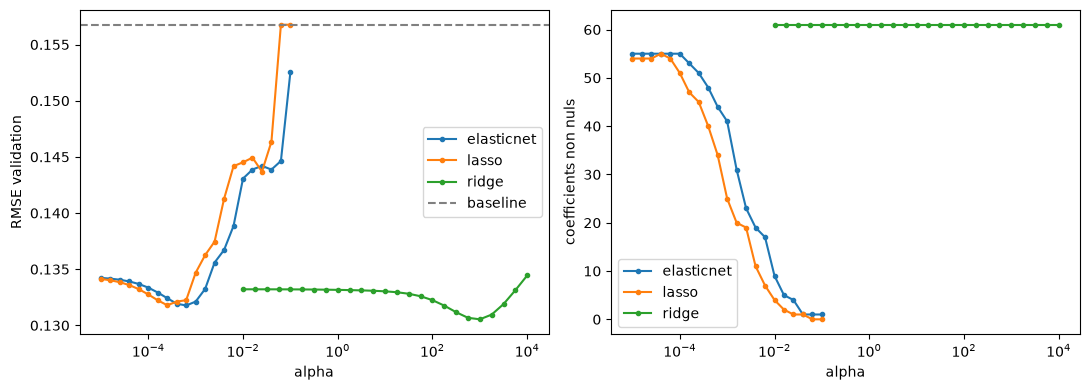

          kind       alpha  val_rmse  n_nonzero
30  elasticnet     0.00063   0.13177         44
7        lasso     0.00025   0.13179         45
62       ridge  1000.00000   0.13054         61


In [6]:
import time

grids = {"lasso": np.logspace(-5, -1, 21),
         "elasticnet": np.logspace(-5, -1, 21),
         "ridge": np.logspace(-2, 4, 25)}

t0 = time.time()
rows = []
for kind, alphas in grids.items():
    for a in alphas:
        m, r = run(kind, a, L1_RATIO, show=False)
        rows.append({"kind": kind, "alpha": a, "val_rmse": r["val"]["rmse"],
                     "n_nonzero": int((np.abs(m.coef_) > 0).sum())})
    print(f"{kind} terminé ({time.time() - t0:.0f} s)")
sweep = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for kind, g in sweep.groupby("kind"):
    ax[0].plot(g["alpha"], g["val_rmse"], marker="o", ms=3, label=kind)
    ax[1].plot(g["alpha"], g["n_nonzero"], marker="o", ms=3, label=kind)
ax[0].axhline(baseline_val["rmse"], color="grey", ls="--", label="baseline")
for a_ in ax:
    a_.set_xscale("log"); a_.set_xlabel("alpha"); a_.legend()
ax[0].set_ylabel("RMSE validation"); ax[1].set_ylabel("coefficients non nuls")
plt.tight_layout(); plt.show()

print(sweep.loc[sweep.groupby("kind")["val_rmse"].idxmin()].round(5))

**Conclusion pratique** : la limite ne vient pas du choix Ridge/Lasso/Elastic Net, mais de ce qu’un modèle linéaire sans interactions peut exprimer. Les trois plafonnent autour de 0,137 à 0,138. Pour ton compte rendu, la raison est que le modèle ne sait pas quelle votation est populaire, seulement à quoi ressemble la commune. C’est ce que les interactions (partis × domaine de l’objet) pourraient améliorer.

## 5. Comparaison sur la validation et coefficients

Hyperparamètres retenus d'après la courbe de validation : Lasso et Elastic Net à `alpha = 1e-5` (le minimum de la grille, mais la courbe y est plate),
Ridge à `alpha ≈ 18`. Les coefficients des variables standardisées sont comparables entre eux ; ceux des variables catégorielles
(0/1, non standardisées) se lisent différemment.

              rmse     mae   mae_pp      r2  n_nonzero
lasso       0.1341  0.1072  10.7228  0.2674       54.0
elasticnet  0.1342  0.1073  10.7292  0.2664       55.0
ridge       0.1329  0.1062  10.6217  0.2803       61.0
baseline    0.1568  0.1317  13.1725 -0.0007        0.0


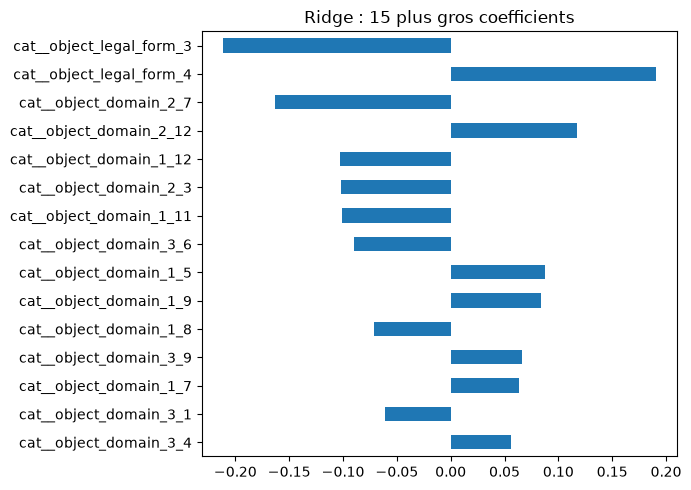

Coefficients nuls : ['flag__statpop_missing']


In [7]:
BEST = {"lasso": dict(alpha=1e-5),
        "elasticnet": dict(alpha=1e-5, l1_ratio=0.5),
        "ridge": dict(alpha=18)}

fitted, rows = {}, {}
for kind, p in BEST.items():
    m, r = run(kind, p["alpha"], p.get("l1_ratio", 0.5), show=False)
    fitted[kind] = m
    rows[kind] = {**r["val"], "n_nonzero": int((np.abs(m.coef_) > 0).sum())}
rows["baseline"] = {**baseline_val, "n_nonzero": 0}
print(pd.DataFrame(rows).T.round(4))

coefs = pd.Series(fitted["ridge"].coef_, index=feat_names).sort_values(key=np.abs, ascending=False)
coefs.head(15)[::-1].plot.barh(figsize=(7, 5), title="Ridge : 15 plus gros coefficients")
plt.tight_layout(); plt.show()
print("Coefficients nuls :", list(coefs[coefs == 0].index))

## 6. Ablation 

On entraîne un Ridge (`alpha = 18`) sur trois jeux de variables et on compare la RMSE sur la **validation** (le test reste intact).

- **Objet seul** : forme juridique et domaines (identiques pour toutes les communes d'une même votation).
- **Commune seule** : tout le reste (démographie, partis, typologies, historique).

In [8]:
obj_cols = [c for c in cat if c.startswith("object_")]
groups = {
    "tout": features,
    "objet seul": obj_cols,
    "commune seule": [c for c in features if c not in obj_cols],
}

def build_pre(cols):
    return ColumnTransformer([
        ("party", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                            ("sc", StandardScaler())]), [c for c in party if c in cols]),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), [c for c in num if c in cols]),
        ("flag", "passthrough", [c for c in flags if c in cols]),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="none")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=50,
                                               sparse_output=False))]), [c for c in cat if c in cols]),
    ])

abl = {"baseline": baseline_val}
for name, cols in groups.items():
    p_ = build_pre(cols)
    A_tr = p_.fit_transform(X_tr[cols])
    A_val = p_.transform(X_val[cols])
    m_ = Ridge(alpha=18).fit(A_tr, y_tr)
    abl[name] = metrics(y_val, m_.predict(A_val))

print(pd.DataFrame(abl).T.round(4))

                 rmse     mae   mae_pp      r2
baseline       0.1568  0.1317  13.1725 -0.0007
tout           0.1329  0.1062  10.6217  0.2803
objet seul     0.1350  0.1098  10.9813  0.2584
commune seule  0.1557  0.1316  13.1552  0.0125


## 7. Interactions commune × domaine de l'objet

Section 7 : les variables communales n'apportent presque rien en additif, alors que leur effet doit dépendre du type de votation
(urbain/rural, région linguistique, partis...). On ajoute donc les produits **variables communales standardisées × domaine principal
(`object_domain_1`)**, puis on règle `alpha` sur la validation comme avant.

In [9]:
LEFT = ("party__", "num__", "cat__urban_rural", "cat__language_region")
RIGHT = "cat__object_domain_1_"

def make_interactions(Xt, names):
    names = np.asarray(names)
    L = [i for i, n in enumerate(names) if n.startswith(LEFT)]
    R = [i for i, n in enumerate(names) if n.startswith(RIGHT)]
    cols = [(Xt[:, i] * Xt[:, j]).astype("float32") for i in L for j in R]
    labels = [f"{names[i]} x {names[j]}" for i in L for j in R]
    return np.column_stack(cols), labels

Itr, inames = make_interactions(Xtr_t, feat_names)
Ival, _ = make_interactions(Xval_t, feat_names)
Ztr = np.hstack([Xtr_t.astype("float32"), Itr])
Zval = np.hstack([Xval_t.astype("float32"), Ival])
z_names = np.concatenate([feat_names, inames])
print("Avec interactions :", Ztr.shape, f"({Ztr.nbytes / 1e6:.0f} Mo)")

rows = []
for a in np.logspace(0, 4, 13):
    m_ = Ridge(alpha=a).fit(Ztr, y_tr)
    rows.append({"kind": "ridge", "alpha": a, **metrics(y_val, m_.predict(Zval))})
for a in np.logspace(-5, -2, 10):
    m_ = Lasso(alpha=a, max_iter=50000, precompute=True).fit(Ztr, y_tr)
    rows.append({"kind": "lasso", "alpha": a, **metrics(y_val, m_.predict(Zval)),
                 "n_nonzero": int((np.abs(m_.coef_) > 0).sum())})
sw2 = pd.DataFrame(rows)
print(sw2.loc[sw2.groupby("kind")["mae_pp"].idxmin()].round(4))

ref = metrics(y_val, Ridge(alpha=1).fit(Xtr_t, y_tr).predict(Xval_t))
print(f"Pour mémoire, sans interactions : ridge (alpha=1) {ref['mae_pp']:.3f} pp | baseline {baseline_val['mae_pp']:.3f} pp")

Avec interactions : (174571, 350) (244 Mo)
     kind      alpha    rmse     mae   mae_pp      r2  n_nonzero
18  lasso     0.0005  0.1298  0.1034  10.3424  0.3140      104.0
10  ridge  2154.4347  0.1302  0.1036  10.3554  0.3102        NaN
Pour mémoire, sans interactions : ridge (alpha=1) 10.638 pp | baseline 13.173 pp


## 8. Validation croisée temporelle dans le train

Le prétraitement et les hyperparamètres se choisissent ici, avec des plis en fenêtre croissante à l'intérieur du train uniquement (2012-2020), en MAE (points de pourcentage). La validation 2021-2022 sert ensuite à comparer les modèles entre eux, pas à les régler.

In [10]:
N_FOLDS = 5
pool_dates = train_dates                       # validation croisée dans l'entraînement seulement
Xp = X_tr.reset_index(drop=True)
yp = y_tr.reset_index(drop=True)
dp = dates[is_tr].reset_index(drop=True)

chunks = np.array_split(pool_dates, N_FOLDS + 1)    # fenêtre croissante : fold k = entraîner sur 0..k-1, valider sur k
res = []
for k in range(1, N_FOLDS + 1):
    tr_m = dp.isin(np.concatenate(chunks[:k])).to_numpy()
    va_m = dp.isin(chunks[k]).to_numpy()
    p_ = clone(pre)
    A_tr, A_va = p_.fit_transform(Xp[tr_m]), p_.transform(Xp[va_m])
    row = {"fold": k, "valide_dès": str(pd.Timestamp(chunks[k][0]).date()),
           "baseline": metrics(yp[va_m], np.full(va_m.sum(), yp[tr_m].mean()))["mae_pp"]}
    for kind, prm in BEST.items():
        m_ = make_model(kind, prm["alpha"], prm.get("l1_ratio", 0.5)).fit(A_tr, yp[tr_m])
        row[kind] = metrics(yp[va_m], m_.predict(A_va))["mae_pp"]
    res.append(row)

cv = pd.DataFrame(res)
print(cv.round(4).to_string(index=False))
print("\nMAE (pp) moyenne ± écart-type sur les folds :")
print(cv[["baseline", "lasso", "elasticnet", "ridge"]].agg(["mean", "std"]).round(4))
print("\nRidge meilleur que le Lasso dans", int((cv["ridge"] < cv["lasso"]).sum()), "folds sur", N_FOLDS)

 fold valide_dès  baseline   lasso  elasticnet   ridge
    1 2013-06-09   18.1899 25.0676     24.4996 23.4201
    2 2014-09-28   17.2781 14.7142     14.7179 14.6821
    3 2016-06-05   14.6574 14.4023     15.0093 15.1713
    4 2017-09-24   19.4519 16.9332     16.9421 16.7751
    5 2019-02-10   12.3660 11.2684     11.2784 11.3629

MAE (pp) moyenne ± écart-type sur les folds :
      baseline    lasso  elasticnet    ridge
mean   16.3887  16.4772     16.4895  16.2823
std     2.8547   5.2093      4.9207   4.4493

Ridge meilleur que le Lasso dans 3 folds sur 5


In [11]:
masks = [(dp.isin(np.concatenate(chunks[:k])).to_numpy(), dp.isin(chunks[k]).to_numpy())
         for k in range(1, N_FOLDS + 1)]
N_COMM = 2104   # communes par votation

def build_pre2(cat_cols, min_freq):
    return ColumnTransformer([
        ("party", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                            ("sc", StandardScaler())]), party),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num),
        ("flag", "passthrough", flags),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="none")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=min_freq,
                                               sparse_output=False))]), cat_cols),
    ])

cat_no23 = [c for c in cat if c not in ("object_domain_2", "object_domain_3")]
VARIANTS = {
    "actuel": (cat, 50),
    ">= 3 votations": (cat, 3 * N_COMM),
    "domaine 1 seul": (cat_no23, 50),
    "domaine 1 seul + >= 3 votations": (cat_no23, 3 * N_COMM),
}

rows = {"baseline": [metrics(yp[v], np.full(v.sum(), yp[t].mean()))["mae_pp"] for t, v in masks]}
for vname, (cols_, mf) in VARIANTS.items():
    scores = {18: [], 300: []}
    for t, v in masks:
        p_ = build_pre2(cols_, mf)
        A_t, A_v = p_.fit_transform(Xp[t]), p_.transform(Xp[v])
        for a in scores:
            scores[a].append(metrics(yp[v], Ridge(alpha=a).fit(A_t, yp[t]).predict(A_v))["mae_pp"])
    for a, s in scores.items():
        rows[f"{vname} | alpha={a}"] = s

tab = pd.DataFrame(rows, index=[f"fold {k}" for k in range(1, N_FOLDS + 1)]).T
tab["moy. folds 2-5"] = tab[[f"fold {k}" for k in range(2, N_FOLDS + 1)]].mean(axis=1)
print(tab.round(4))

                                              fold 1   fold 2   fold 3  \
baseline                                     18.1899  17.2781  14.6574   
actuel | alpha=18                            23.4201  14.6821  15.1713   
actuel | alpha=300                           20.3782  14.6195  14.2908   
>= 3 votations | alpha=18                    16.6002  14.4720  12.0901   
>= 3 votations | alpha=300                   16.5028  14.4715  12.0215   
domaine 1 seul | alpha=18                    21.7757  12.3941  12.1593   
domaine 1 seul | alpha=300                   21.4446  12.4193  11.8761   
domaine 1 seul + >= 3 votations | alpha=18   16.6445  12.9691  10.5869   
domaine 1 seul + >= 3 votations | alpha=300  16.6051  12.9937  10.5563   

                                              fold 4   fold 5  moy. folds 2-5  
baseline                                     19.4519  12.3660         15.9383  
actuel | alpha=18                            16.7751  11.3629         14.4979  
actuel | alpha=300 

In [12]:
def cv_grid(cat_cols, min_freq, grid):
    out = {}
    for t, v in masks:
        p_ = build_pre2(cat_cols, min_freq)
        A_t, A_v = p_.fit_transform(Xp[t]), p_.transform(Xp[v])
        for kind, a in grid:
            m_ = make_model(kind, a, 0.5).fit(A_t, yp[t])
            out.setdefault(f"{kind} | alpha={a:g}", []).append(metrics(yp[v], m_.predict(A_v))["mae_pp"])
    return out

GRID = [("ridge", 18), ("ridge", 300), ("ridge", 1000),
        ("lasso", 1e-5), ("lasso", 1e-4), ("lasso", 1e-3),
        ("elasticnet", 1e-4), ("elasticnet", 1e-3)]
CANDIDATES = {
    "A : domaine 1 seul, >= 3 votations": (cat_no23, 3 * N_COMM),
    "B : tous les domaines, >= 3 votations": (cat, 3 * N_COMM),
}
idx = [f"fold {k}" for k in range(1, N_FOLDS + 1)]
base = [metrics(yp[v], np.full(v.sum(), yp[t].mean()))["mae_pp"] for t, v in masks]

for name, (cols_, mf) in CANDIDATES.items():
    tab = pd.DataFrame({"baseline": base, **cv_grid(cols_, mf, GRID)}, index=idx).T
    tab["moy. 2-5"] = tab[idx[1:]].mean(axis=1)
    tab["moy. 1-5"] = tab[idx].mean(axis=1)
    print("\n" + name)
    print(tab.round(4).to_string())


A : domaine 1 seul, >= 3 votations
                            fold 1   fold 2   fold 3   fold 4   fold 5  moy. 2-5  moy. 1-5
baseline                   18.1899  17.2781  14.6574  19.4519  12.3660   15.9383   16.3887
ridge | alpha=18           16.6445  12.9691  10.5869  13.2555  10.8175   11.9072   12.8547
ridge | alpha=300          16.6051  12.9937  10.5563  13.2643  10.7867   11.9002   12.8412
ridge | alpha=1000         16.5501  13.0800  10.5056  13.3152  10.7187   11.9049   12.8339
lasso | alpha=1e-05        16.0422  12.9516  10.5190  13.2564  10.8160   11.8857   12.7170
lasso | alpha=0.0001       16.0411  12.9461  10.5217  13.2652  10.7904   11.8808   12.7129
lasso | alpha=0.001        16.0438  12.9732  10.4600  13.3230  10.5810   11.8343   12.6762
elasticnet | alpha=0.0001  16.1692  12.9512  10.5192  13.2602  10.8032   11.8834   12.7406
elasticnet | alpha=0.001   16.5226  12.9568  10.5069  13.3009  10.6811   11.8614   12.7937

B : tous les domaines, >= 3 votations
               

In [13]:
def build_pre3(k_main, k_23):
    def cat_pipe(mf):
        return Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="none")),
                         ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=mf,
                                              sparse_output=False))])
    return ColumnTransformer([
        ("party", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                            ("sc", StandardScaler())]), party),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("sc", StandardScaler())]), num),
        ("flag", "passthrough", flags),
        ("cat", cat_pipe(k_main * N_COMM), cat_no23),
        ("cat23", cat_pipe(k_23 * N_COMM), ["object_domain_2", "object_domain_3"]),
    ])

GRID3 = [("ridge", 1000), ("ridge", 3000), ("ridge", 10000),
         ("lasso", 1e-3), ("lasso", 3e-3), ("lasso", 1e-2),
         ("elasticnet", 1e-3), ("elasticnet", 3e-3)]

for k23 in (6, 10, 15):
    out = {}
    for t, v in masks:
        p_ = build_pre3(3, k23)
        A_t, A_v = p_.fit_transform(Xp[t]), p_.transform(Xp[v])
        for kind, a in GRID3:
            m_ = make_model(kind, a, 0.5).fit(A_t, yp[t])
            out.setdefault(f"{kind} | alpha={a:g}", []).append(metrics(yp[v], m_.predict(A_v))["mae_pp"])
    tab = pd.DataFrame({"baseline": base, **out}, index=idx).T
    tab["moy. 2-5"] = tab[idx[1:]].mean(axis=1)
    tab["moy. 1-5"] = tab[idx].mean(axis=1)
    print(f"\nC : domaines 2/3 à >= {k23} votations (reste >= 3)")
    print(tab.round(4).to_string())


C : domaines 2/3 à >= 6 votations (reste >= 3)
                           fold 1   fold 2   fold 3   fold 4   fold 5  moy. 2-5  moy. 1-5
baseline                  18.1899  17.2781  14.6574  19.4519  12.3660   15.9383   16.3887
ridge | alpha=1000        16.5336  14.1591  10.9792  13.5633  10.5822   12.3209   13.1635
ridge | alpha=3000        16.5517  14.3140  10.8584  13.8830  10.4725   12.3820   13.2159
ridge | alpha=10000       16.9784  14.7920  10.9696  14.7441  10.3049   12.7026   13.5578
lasso | alpha=0.001       15.9003  13.9273  10.8153  13.5090  10.5216   12.1933   12.9347
lasso | alpha=0.003       16.0705  13.9461  10.4407  13.6155  10.2642   12.0666   12.8674
lasso | alpha=0.01        16.4323  13.6866  10.5918  14.0823  10.3912   12.1880   13.0368
elasticnet | alpha=0.001  16.5242  13.8799  10.8576  13.4815  10.5600   12.1947   13.0606
elasticnet | alpha=0.003  16.5018  13.9421  10.6282  13.5558  10.3448   12.1177   12.9945

C : domaines 2/3 à >= 10 votations (reste >= 3)
   

### Export des prédictions de validation
Prédictions de validation écrites dans `reports/generated/regularized_linear/`

In [14]:
PRES = {"init": lambda: clone(pre),                                  # prétraitement de départ (min_frequency=50)
        "A": lambda: build_pre2(cat_no23, 3 * N_COMM)}               # A : domaine 1 seul, modalités >= 3 votations (section 8)
CHOICES = {   # nom : (modèle, alpha, l1_ratio, prétraitement) ; alphas choisis par la validation croisée du train (section 8)
    "ridge_init": ("ridge", 300, 0.5, "init"),
    "ridge_A": ("ridge", 1000, 0.5, "A"),
    "lasso_A": ("lasso", 1e-3, 0.5, "A"),
    "elasticnet_A": ("elasticnet", 3e-3, 0.5, "A"),
}
val_out = df.loc[is_val, ["municipality_id", "vote_id", DATE_COL, TARGET]].copy()
c = float(y_tr.mean())
preds = {"constant": np.full(len(y_val), c),
         "municipal_history": X_val.history_mean_yes.fillna(c).to_numpy(float)}
fitted_pre = {}
for name, (kind, a, l1, pk) in CHOICES.items():
    if pk not in fitted_pre:
        p_ = PRES[pk]()
        fitted_pre[pk] = (p_.fit_transform(X_tr), p_.transform(X_val))
    A_t, A_v = fitted_pre[pk]
    preds[name] = np.clip(make_model(kind, a, l1).fit(A_t, y_tr).predict(A_v), 0, 1)

rows = []
for name, p in preds.items():
    val_out[name] = p
    err = pd.DataFrame({"vote_id": val_out.vote_id.to_numpy(), "d": val_out[DATE_COL].to_numpy(),
                        "ae": np.abs(y_val.to_numpy(float) - p) * 100})
    rows.append({"model": name, "mae_pp": err.ae.mean(),
                 "mean_object_mae_pp": err.groupby("vote_id").ae.mean().mean(),
                 "mean_date_mae_pp": err.groupby("d").ae.mean().mean()})
scores = pd.DataFrame(rows).set_index("model")
scores["gain_vs_constant_pp"] = scores.loc["constant", "mae_pp"] - scores.mae_pp
scores["gain_vs_history_pp"] = scores.loc["municipal_history", "mae_pp"] - scores.mae_pp
display(scores.round(3))
val_out.to_parquet(OUT_DIR / "validation_predictions.parquet", index=False)
scores.to_csv(OUT_DIR / "validation_metrics.csv")
print("Exporté dans", OUT_DIR.relative_to(REPO))

,mae_pp,mean_object_mae_pp,mean_date_mae_pp,gain_vs_constant_pp,gain_vs_history_pp
model,,,,,
constant,13.173,13.173,13.388,0.000,-0.203
municipal_history,12.970,12.970,13.143,0.203,0.000
ridge_init,10.495,10.495,10.513,2.677,2.475
ridge_A,11.785,11.785,11.657,1.388,1.185
lasso_A,11.616,11.616,11.518,1.557,1.354
elasticnet_A,11.569,11.569,11.485,1.603,1.401


Exporté dans reports\generated\regularized_linear


## 9. Évaluation finale sur le test

À lancer **une seule fois**, quand les choix de la section 9 sont figés. 

In [15]:
BEST = {"lasso": dict(alpha=3e-3),                         
        "elasticnet": dict(alpha=3e-3, l1_ratio=0.5),
        "ridge": dict(alpha=3000)}

pre_final = build_pre3(3, 6)               # modalités >= 3 votations ; domaines 2/3 >= 6 votations (à revoir, section 9)
Xtv_t = pre_final.fit_transform(Xp)        # entraînement seulement (Xp = train)
Xte_t = pre_final.transform(X_te)
names_final = pre_final.get_feature_names_out()

out = OUT_DIR                              # reports/generated/regularized_linear

preds, rows = {}, {"baseline": metrics(y_te, np.full(len(y_te), yp.mean()))}
for kind, p in BEST.items():
    m = make_model(kind, p["alpha"], p.get("l1_ratio", 0.5)).fit(Xtv_t, yp)
    preds[kind] = m.predict(Xte_t)
    rows[kind] = {**metrics(y_te, preds[kind]), "n_nonzero": int((np.abs(m.coef_) > 0).sum())}
    c = pd.Series(m.coef_, index=names_final)
    c[c != 0].sort_values(key=np.abs, ascending=False).to_csv(out / f"coefs_{kind}_final.csv")

res_test = pd.DataFrame(rows).T
res_test.to_csv(out / "metrics_test_final.csv")
print(res_test.round(4))

# MAE (pp) par date de votation (descriptif : ne sert pas à choisir)
d_te = dates[is_te].reset_index(drop=True).dt.date
yt = y_te.to_numpy()
by_date = pd.DataFrame({k: pd.Series(np.abs(yt - p) * 100).groupby(d_te).mean() for k, p in preds.items()})
by_date.insert(0, "baseline", pd.Series(np.abs(yt - yp.mean()) * 100).groupby(d_te).mean())
print("\nMAE (pp) par date de test :")
print(by_date.round(3))

              rmse     mae   mae_pp      r2  n_nonzero
baseline    0.1746  0.1466  14.6640 -0.0010        NaN
lasso       0.1504  0.1202  12.0225  0.2576       17.0
elasticnet  0.1517  0.1213  12.1313  0.2443       20.0
ridge       0.1535  0.1228  12.2835  0.2269       47.0

MAE (pp) par date de test :
            baseline   lasso  elasticnet   ridge
vote_date                                       
2023-06-18    17.846  13.755      13.620  13.580
2024-03-03    18.839  17.686      17.703  17.726
2024-06-09    14.474   9.825      10.479  10.948
2024-09-22    15.914  15.669      15.027  14.850
2024-11-24     9.277   8.008       8.187   8.504
2025-02-09    21.808  12.752      14.786  15.933
2025-09-28    12.047  12.174      11.298  10.737


In [16]:
coefs_all = {k: pd.read_csv(out / f"coefs_{k}_final.csv", index_col=0).iloc[:, 0]
             for k in ("lasso", "elasticnet")}
sel = pd.DataFrame(coefs_all).fillna(0)
sel["groupe"] = np.where(sel.index.str.contains("object_"), "objet", "commune / historique")
sel = sel.sort_values("lasso", key=np.abs, ascending=False)
print(sel.round(4).to_string())

                                            lasso  elasticnet                groupe
cat__object_legal_form_3                  -0.1937     -0.1962                 objet
cat__object_legal_form_4                   0.1487      0.1702                 objet
cat__object_domain_1_6                    -0.0311     -0.0522                 objet
cat23__object_domain_2_10                  0.0269      0.0413                 objet
cat__language_region_1                    -0.0239     -0.0278  commune / historique
cat__object_domain_1_4                     0.0169      0.0355                 objet
cat23__object_domain_2_infrequent_sklearn -0.0130     -0.0314                 objet
num__history_mean_yes                      0.0100      0.0113  commune / historique
cat23__object_domain_2_none               -0.0086     -0.0247                 objet
cat__object_domain_1_8                    -0.0046     -0.0256                 objet
party__party_share_ps                      0.0029      0.0027  commune / his

## Conclusion

**Protocole.** Ridge, Lasso et Elastic Net sont comparés à deux baselines (la moyenne du train, et l'historique communal figé à la fin de 2020) sur les partitions communes de l'équipe : train 2012-2020 (30 dates), validation 2021-2022 (7 dates), test 2023-2025 (7 dates). La métrique est la MAE en points de pourcentage (pp). Les hyperparamètres sont choisis par validation croisée temporelle dans le train. La validation sert à comparer les modèles entre eux.

**Validation (2021-2022), modèles entraînés sur le train seul**

| Modèle | Prétraitement | `alpha` | MAE validation croisée du train (pp) | MAE validation (pp) |
|---|---|---|---|---|
| Constante (moyenne du train) | — | — | 16,39 | 13,17 |
| Historique communal figé | — | — | — | 12,97 |
| Ridge | de départ (`min_frequency = 50`) | 300 | 15,34 | **10,50** |
| Ridge | A (domaine 1 seul, ≥ 3 votations) | 1000 | 12,83 | 11,79 |
| Lasso | A | 1e-3 | **12,68** | 11,62 |
| Elastic Net (`l1_ratio = 0,5`) | A | 3e-3 | 12,76 | 11,57 |

**Test (2023-2025), lu une seule fois**, avec le prétraitement C (≥ 3 votations, ≥ 6 pour les domaines 2 et 3) et les `alpha` hérités de l'ancien protocole, non modifiés depuis :

| Modèle | MAE test (pp) | RMSE test | R² test | Variables non nulles |
|---|---|---|---|---|
| Constante (moyenne du train) | 14,66 | 0,1746 | −0,00 | — |
| Lasso (`alpha = 3e-3`) | **12,02** | 0,1504 | 0,26 | 17 |
| Elastic Net (`alpha = 3e-3`, `l1_ratio = 0,5`) | 12,13 | 0,1517 | 0,24 | 20 |
| Ridge (`alpha = 3000`) | 12,28 | 0,1535 | 0,23 | 47 |

**Résultats**
- **Gain réel contre les baselines.** En validation, les meilleurs modèles gagnent 1,4 à 2,7 pp sur la constante (13,17) et 1,2 à 2,5 pp sur l'historique communal (12,97). En test, le gain sur la constante est de 2,4 à 2,6 pp (environ 16 à 18 %). L'historique communal seul n'apporte presque rien (0,2 pp).
- **Les trois modèles sont équivalents.** Les écarts entre Ridge, Lasso et Elastic Net sont de 0,15 pp en validation croisée et de 0,26 pp en test, ce qui est du bruit pour 7 dates. On ne peut pas désigner un meilleur modèle de la famille linéaire. Le Lasso a l'avantage d'être parcimonieux (17 coefficients non nuls contre 47 pour Ridge).
- **Le signal vient de l'objet de la votation.** Ablation sur la validation : tout 10,62 pp, objet seul 10,98 pp, commune seule 13,16 pp, soit la baseline (13,17). Les coefficients du Lasso le confirment : les plus gros sont la forme juridique de l'objet (`object_legal_form_3` : −0,19 ; `_4` : +0,15). Parmi les variables communales, seules `language_region` (−0,024) et `history_mean_yes` (+0,010) pèsent ; la démographie est à zéro.
- **Un modèle linéaire a peu de données pour l'objet.** Les variables de l'objet sont constantes sur les ~2 100 communes d'une même votation, donc l'échantillon effectif est le nombre de votations, pas de lignes. Avec une courte histoire, le prétraitement de départ mémorise les votations : au premier pli de validation croisée il fait 23 à 25 pp contre 18,2 pour la constante. Exiger qu'une modalité apparaisse dans au moins 3 votations ramène ce pli à 16,0 à 16,6 pp.
- **Les interactions commune × domaine** (section 7) donnent environ 0,3 pp de mieux en validation (10,34 et 10,36 pp contre 10,64 pp). Comme leur `alpha` a été réglé sur la validation, ce gain est optimiste. Il n'est pas retenu tant que la validation croisée du train ne le confirme pas.

**Limites**
- Validation et test ne comptent que 7 dates chacun : les écarts inférieurs à 0,3 pp ne sont pas interprétables.
- Le test a été lu plusieurs fois au cours du projet (protocole précédent, puis ce notebook). Les réglages n'ont pas été modifiés d'après ces lectures, mais le test n'est pas strictement vierge.
- La validation a servi à comparer plusieurs prétraitements et plusieurs modèles : ses chiffres sont légèrement optimistes. Les `alpha` du prétraitement de départ n'ont été testés qu'à 18 et 300 en validation croisée. `l1_ratio` n'a pas été optimisé.
- L'historique communal est figé à la fin de 2020. 24 lignes de validation et 18 lignes de test n'en ont pas, et il vieillit sur 2023-2025.
- Les parts de partis absentes valent 0 (PDC, PBD, Centre fusionnés en un seul bloc). Le boosting laisse les valeurs manquantes telles quelles. C'est un écart de traitement entre les deux modèles.
- Aucune variable n'est validée pour une prévision en temps réel (`strict_forecast_validated` est faux partout). Les classifications Swissvotes et les typologies sont celles du snapshot actuel. Les résultats valent pour une analyse rétrospective.
- Un modèle additif ne capte pas l'interaction entre le profil de la commune et l'orientation de la votation, d'où la piste des recommandations de partis par objet et des modèles non linéaires.